<a href="https://colab.research.google.com/github/paolamrk/Practica3_MachineLearning/blob/main/pracitca_clasificadores_integrante3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 3: Machine Learning — Integrante 3 (K-NN + Naïve Bayes)

Avance correspondiente a los días **3, 4 y 5 de noviembre** del cronograma:

| Día | Actividad | Sección |
|---|---|---|
| 3 nov | Preparar bibliotecas y entorno de trabajo | 1 |
| 4 nov | Análisis exploratorio y normalización | 2 |
| 5 nov | Programar K-NN desde cero | 3 |

> Ejecuta las celdas en orden (*Entorno de ejecución → Ejecutar todas*).

## 1. Entorno de trabajo (3 de noviembre)

Esta sección es la **configuración común** del equipo. Los tres integrantes deben copiar la celda de configuración
(bibliotecas, semilla, tamaño del Hold Out y número de folds) al inicio de su Colab, para que todos obtengan
**exactamente las mismas particiones** y los resultados sean comparables.

In [12]:
import time
import copy
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_wine, make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.neighbors import KNeighborsClassifier   # solo para VALIDAR el K-NN propio
from sklearn.naive_bayes import GaussianNB          # se usará el 6 de noviembre

warnings.filterwarnings("ignore")

### 1.2 Configuración común del equipo

Estos valores **no deben cambiarse** sin avisar a los demás integrantes.

In [13]:
SEMILLA   = 42     # misma semilla para los tres integrantes
TEST_SIZE = 0.30   # Hold Out 70/30
N_FOLDS   = 5      # K-Fold Cross-Validation (k = 5)

np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print(f"Python       {platform.python_version()}")
for nombre, mod in [("numpy", np), ("pandas", pd), ("scikit-learn", sklearn),
                    ("matplotlib", plt.matplotlib), ("seaborn", sns)]:
    print(f"{nombre:<12} {mod.__version__}")

Python       3.13.18
numpy        2.4.6
pandas       2.2.3
scikit-learn 1.6.1
matplotlib   3.10.0
seaborn      0.13.2


### 1.3 Archivo `requirements.txt` para el repositorio

Genera el archivo con las versiones exactas de este entorno. Este se sube al repositorio de GitHub para que cualquiera pueda reproducir los resultados.

In [14]:
paquetes = {"numpy": np, "pandas": pd, "scikit-learn": sklearn,
            "matplotlib": plt.matplotlib, "seaborn": sns}
with open("requirements.txt", "w") as f:
    for nombre, mod in paquetes.items():
        f.write(f"{nombre}=={mod.__version__}\n")
print(open("requirements.txt").read())

numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2



### 1.4 Funciones de evaluación compartidas

Todas las evaluaciones del equipo deberían pasar por estas funciones, así cada modelo se mide igual:

- **Hold Out 70/30 estratificado** (misma proporción de clases en entrenamiento y prueba).
- **K-Fold estratificado** con `shuffle=True` y la semilla común.
- La **normalización se ajusta solo con los datos de entrenamiento** de cada partición (evita *data leakage*).
- Se mide por separado el tiempo de entrenamiento (`fit`) y de predicción (`predict`).
- Métricas: exactitud, precisión, recall y F1 (promedio *macro*, porque hay 3 clases).

Funcionan con cualquier objeto que tenga `fit(X, y)` y `predict(X)`: tanto los clasificadores desde cero
como los de scikit-learn.

In [15]:
def calcular_metricas(y_real, y_pred):
    return {
        "exactitud": accuracy_score(y_real, y_pred),
        "precision": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "recall":    recall_score(y_real, y_pred, average="macro", zero_division=0),
        "f1":        f1_score(y_real, y_pred, average="macro", zero_division=0),
    }


def dividir_holdout(X, y):
    # Particion Hold Out 70/30 estratificada, identica para todo el equipo.
    return train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEMILLA)


def obtener_kfold():
    return StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)


def _entrenar_y_medir(modelo, X_tr, y_tr, X_te, y_te, escalar):
    modelo = copy.deepcopy(modelo)            # modelo nuevo en cada particion
    if escalar:
        esc = StandardScaler().fit(X_tr)      # se ajusta SOLO con entrenamiento
        X_tr, X_te = esc.transform(X_tr), esc.transform(X_te)
    t0 = time.perf_counter(); modelo.fit(X_tr, y_tr)
    t1 = time.perf_counter(); y_pred = modelo.predict(X_te)
    t2 = time.perf_counter()
    res = calcular_metricas(y_te, y_pred)
    res["t_fit_ms"] = (t1 - t0) * 1000
    res["t_pred_ms"] = (t2 - t1) * 1000
    return res, y_pred


def evaluar_holdout(modelo, X, y, escalar=True):
    X, y = np.asarray(X, dtype=float), np.asarray(y)
    X_tr, X_te, y_tr, y_te = dividir_holdout(X, y)
    res, y_pred = _entrenar_y_medir(modelo, X_tr, y_tr, X_te, y_te, escalar)
    return res, (y_te, y_pred)


def evaluar_kfold(modelo, X, y, escalar=True):
    X, y = np.asarray(X, dtype=float), np.asarray(y)
    filas = []
    for tr, te in obtener_kfold().split(X, y):
        res, _ = _entrenar_y_medir(modelo, X[tr], y[tr], X[te], y[te], escalar)
        filas.append(res)
    df = pd.DataFrame(filas)
    resumen = df.mean().to_dict()
    resumen.update({f"{c}_std": df[c].std() for c in ["exactitud", "f1"]})
    return resumen, df

print("Funciones de evaluación listas.")

Funciones de evaluación listas.


## 2. Análisis exploratorio y normalización (4 de noviembre)

Reparto del día: el Integrante 1 genera el dataset sintético, el Integrante 2 carga Wine y **a mí me toca el
análisis exploratorio (EDA) y la normalización**. Por eso las funciones de esta sección son genéricas:
reciben cualquier `DataFrame` con una columna `clase` y se aplican a los dos datasets.

### 2.1 Carga de los datasets

In [16]:
# Dataset benchmark: Wine (178 muestras, 13 rasgos numericos reales, 3 clases)
wine = load_wine()
df_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
df_wine["clase"] = wine.target
df_wine.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


**Dataset sintético provisional.** Mientras el Integrante 1 entrega su versión, usaré este generador para poder
avanzar. Cuando llegue el definitivo solo hay que reemplazar `df_sint` (con una columna `clase`) y volver a
ejecutar todo.

El "ruido estructurado" que incluye (ruido que sigue un patrón, no puramente aleatorio):
- **Heterocedástico**: la varianza del ruido en `x1` depende de la clase.
- **Correlacionado**: `x2` arrastra una parte de `x1`.
- **Outliers**: 2 % de las muestras con valores extremos en `x3`.
- **Etiquetas ruidosas**: 5 % de etiquetas cambiadas al azar (`flip_y`).
- **Escalas distintas**: `x4` está en una escala 100 veces mayor (justifica la normalización).

In [17]:
def generar_sintetico_provisional(n=600, semilla=SEMILLA):
    X, y = make_classification(n_samples=n, n_features=6, n_informative=4, n_redundant=1,
                               n_classes=3, n_clusters_per_class=2, class_sep=1.2,
                               flip_y=0.05, random_state=semilla)
    rng = np.random.default_rng(semilla)
    X[:, 0] += rng.normal(0, 1, n) * np.array([0.3, 0.6, 1.0])[y]   # heterocedastico
    X[:, 1] += 0.8 * X[:, 0] + rng.normal(0, 0.2, n)                   # correlacionado
    idx = rng.choice(n, int(0.02 * n), replace=False)
    X[idx, 2] += rng.normal(0, 8, len(idx))                            # outliers
    X[:, 3] *= 100                                                     # otra escala
    df = pd.DataFrame(X, columns=[f"x{i+1}" for i in range(X.shape[1])])
    df["clase"] = y
    return df

df_sint = generar_sintetico_provisional()   # <-- reemplazar por el del Integrante 1
df_sint.head()

,x1,x2,x3,x4,x5,x6,clase
0,-1.552130,-1.765474,-0.901782,-143.813715,-0.674574,-2.124807,0
1,0.885420,1.883054,1.560950,33.647854,-1.336821,1.664977,1
2,1.323843,2.570635,-0.262296,220.742903,0.368175,0.667913,0
3,-0.574604,-3.066337,-0.741393,-33.887769,3.174750,0.017572,2
4,0.348345,-3.174127,-0.067007,-354.917991,1.265101,-0.794606,1


### 2.2 Funciones de análisis exploratorio

In [19]:
def resumen_dataset(df, nombre, objetivo="clase"):
    rasgos = df.drop(columns=objetivo)
    print(f"===== {nombre} =====")
    print(f"Muestras: {df.shape[0]}  |  Rasgos: {rasgos.shape[1]}  |  Clases: {df[objetivo].nunique()}")
    print(f"Valores nulos: {int(df.isnull().sum().sum())}  |  Filas duplicadas: {int(df.duplicated().sum())}")
    print("\nDistribución de clases:")
    conteo = df[objetivo].value_counts().sort_index()
    print(pd.DataFrame({"muestras": conteo, "%": (100 * conteo / len(df)).round(1)}))
    return rasgos.describe().T.round(3)


def graficar_clases(df, nombre, objetivo="clase"):
    ax = df[objetivo].value_counts().sort_index().plot(kind="bar", color="#4C72B0", figsize=(5, 3.5))
    ax.set_title(f"{nombre}: muestras por clase"); ax.set_xlabel("Clase"); ax.set_ylabel("Muestras")
    plt.xticks(rotation=0); plt.tight_layout(); plt.show()


def graficar_histogramas(df, nombre, objetivo="clase", columnas=4):
    rasgos = [c for c in df.columns if c != objetivo]
    filas = int(np.ceil(len(rasgos) / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(4 * columnas, 3 * filas))
    axes = np.atleast_1d(axes).ravel()
    for ax, r in zip(axes, rasgos):
        sns.histplot(data=df, x=r, hue=objetivo, element="step", stat="density",
                     common_norm=False, palette="Set2", ax=ax, legend=(r == rasgos[0]))
        ax.set_title(r, fontsize=10); ax.set_xlabel("")
    for ax in axes[len(rasgos):]:
        ax.remove()
    fig.suptitle(f"{nombre}: distribución de cada rasgo por clase", y=1.01)
    plt.tight_layout(); plt.show()


def graficar_boxplots(df, nombre, objetivo="clase", titulo_extra=""):
    plt.figure(figsize=(max(8, 0.8 * (df.shape[1] - 1)), 4))
    sns.boxplot(data=df.drop(columns=objetivo), orient="v", color="#8DA0CB")
    plt.xticks(rotation=45, ha="right")
    plt.title(f"{nombre}: boxplot de rasgos {titulo_extra}")
    plt.tight_layout(); plt.show()


def graficar_correlacion(df, nombre, objetivo="clase"):
    corr = df.drop(columns=objetivo).corr()
    n = corr.shape[0]
    plt.figure(figsize=(0.65 * n + 3, 0.55 * n + 2))
    sns.heatmap(corr, annot=n <= 13, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
                square=True, annot_kws={"size": 7})
    plt.title(f"{nombre}: matriz de correlación"); plt.tight_layout(); plt.show()
    pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
                 .abs().sort_values(ascending=False))
    print("Pares de rasgos más correlacionados (|r|):")
    print(pares.head(5).round(3).to_string())


def contar_outliers_iqr(df, objetivo="clase"):
    rasgos = df.drop(columns=objetivo)
    q1, q3 = rasgos.quantile(0.25), rasgos.quantile(0.75)
    iqr = q3 - q1
    fuera = (rasgos < q1 - 1.5 * iqr) | (rasgos > q3 + 1.5 * iqr)
    tabla = pd.DataFrame({"outliers": fuera.sum(), "%": (100 * fuera.mean()).round(1)})
    return tabla[tabla["outliers"] > 0].sort_values("outliers", ascending=False)

### 2.3 EDA — Wine

In [20]:
resumen_dataset(df_wine, "Wine")

===== Wine =====
Muestras: 178  |  Rasgos: 13  |  Clases: 3
Valores nulos: 0  |  Filas duplicadas: 0

Distribución de clases:
       muestras     %
clase                
0            59  33.1
1            71  39.9
2            48  27.0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


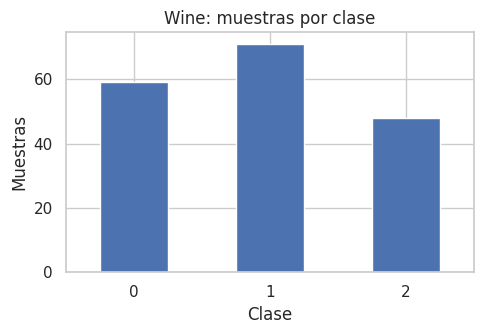

In [21]:
graficar_clases(df_wine, "Wine")

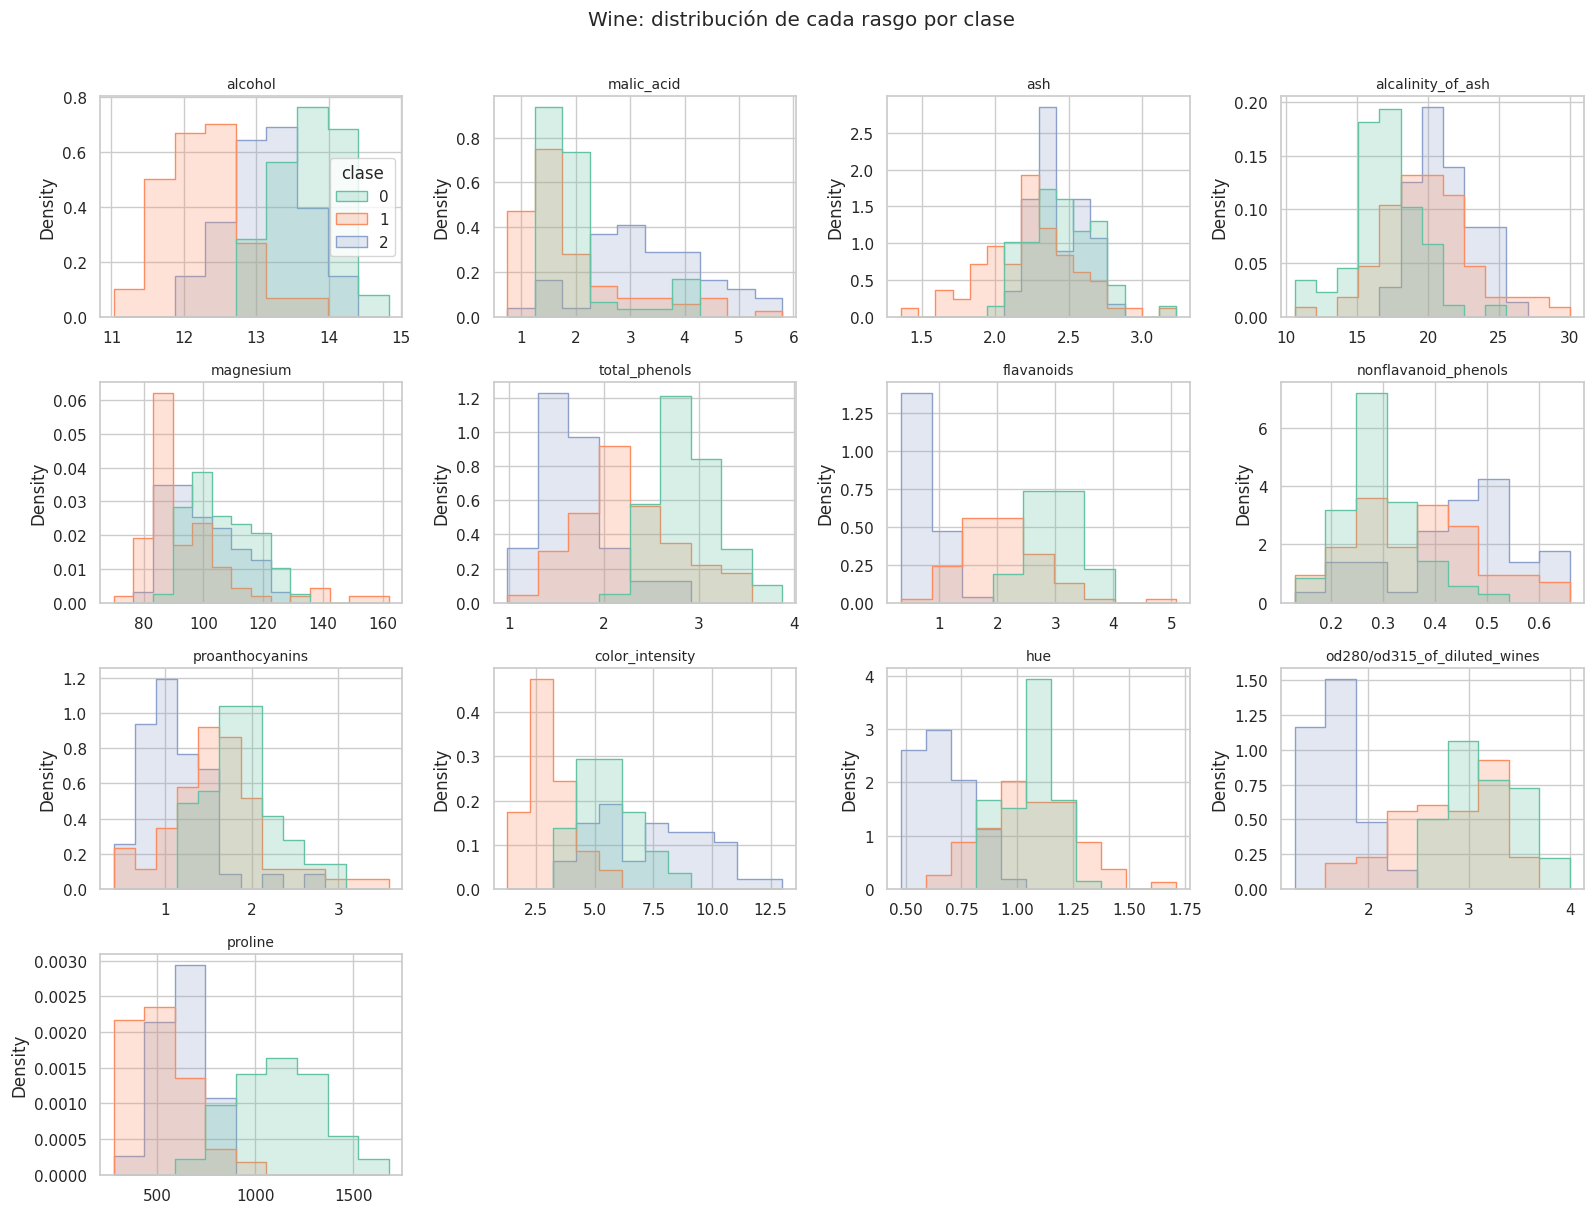

In [22]:
graficar_histogramas(df_wine, "Wine")

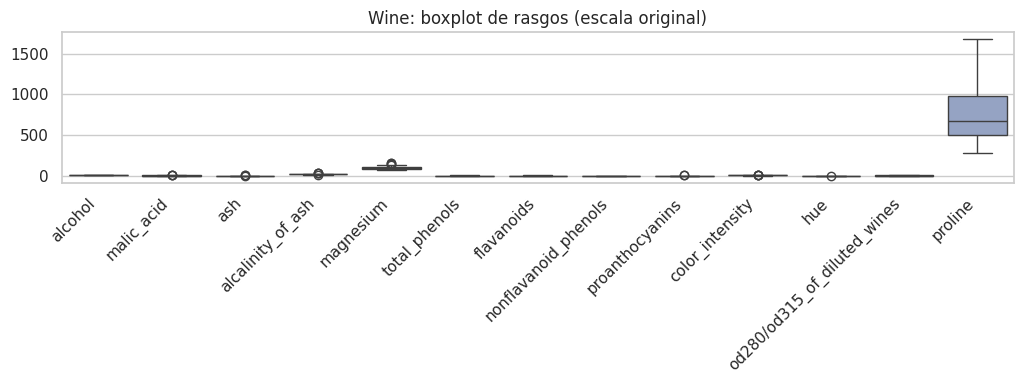

In [23]:
graficar_boxplots(df_wine, "Wine", titulo_extra="(escala original)")

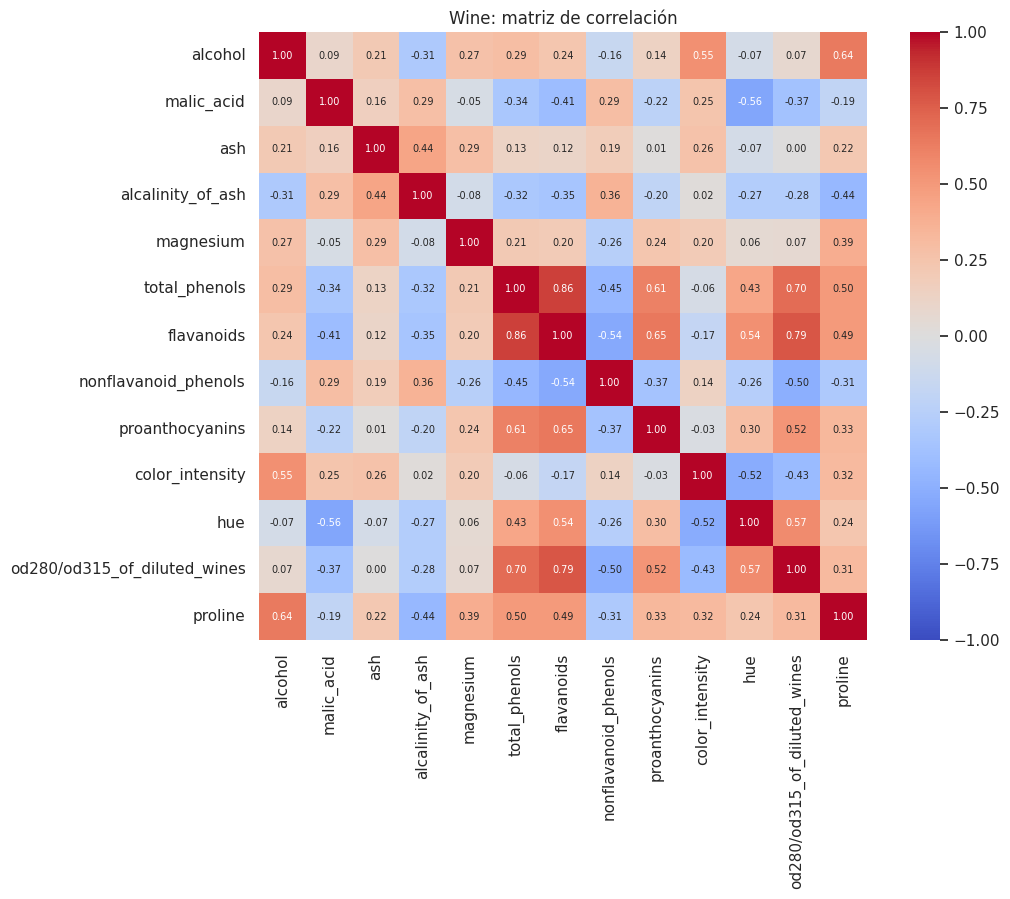

Pares de rasgos más correlacionados (|r|):
total_phenols  flavanoids                      0.865
flavanoids     od280/od315_of_diluted_wines    0.787
total_phenols  od280/od315_of_diluted_wines    0.700
flavanoids     proanthocyanins                 0.653
alcohol        proline                         0.644


In [24]:
graficar_correlacion(df_wine, "Wine")

In [25]:
contar_outliers_iqr(df_wine)

,outliers,%
alcalinity_of_ash,4,2.2
color_intensity,4,2.2
magnesium,4,2.2
ash,3,1.7
malic_acid,3,1.7
proanthocyanins,2,1.1
hue,1,0.6


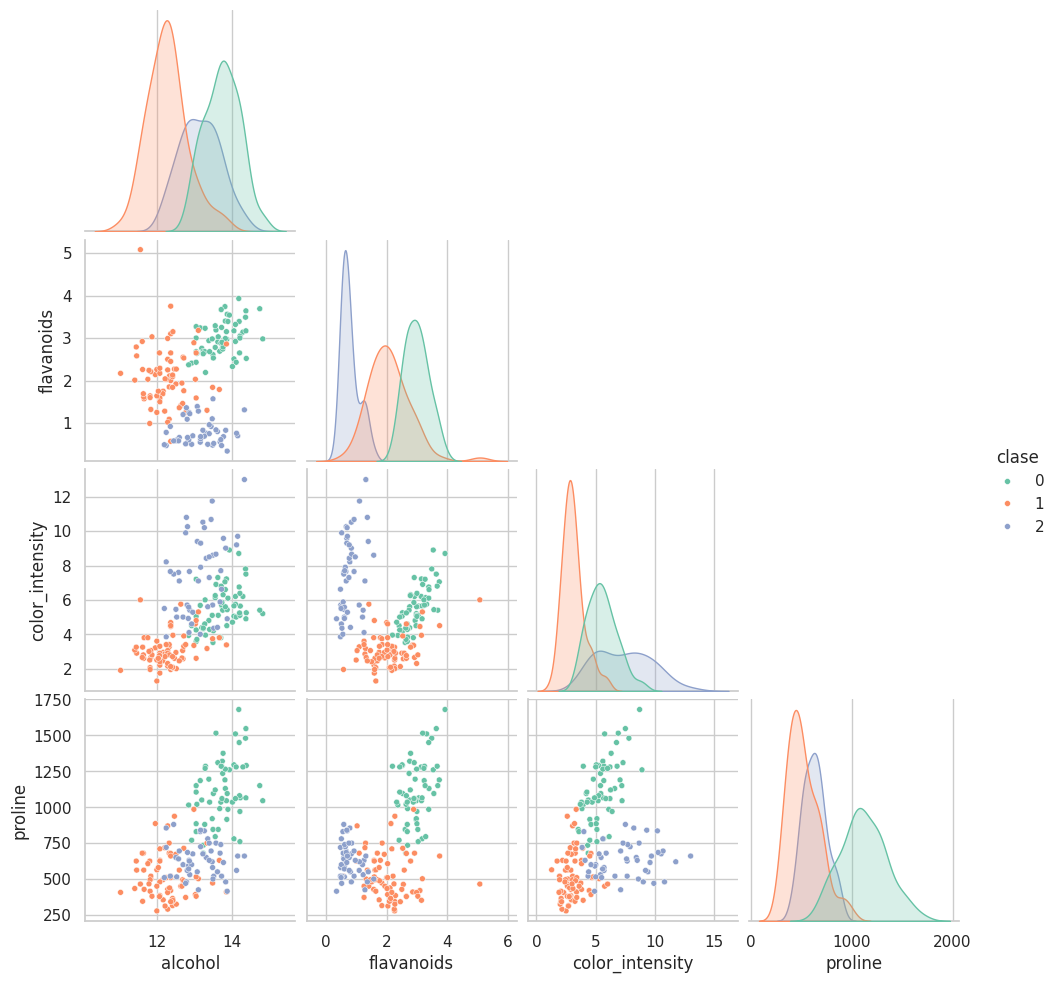

In [26]:
# Vista conjunta de 4 rasgos que separan bien las clases
sns.pairplot(df_wine[["alcohol", "flavanoids", "color_intensity", "proline", "clase"]],
             hue="clase", palette="Set2", corner=True, plot_kws={"s": 18})
plt.show()

**Observaciones Wine** (revísalas con tus gráficas antes de pasarlas al reporte):
- No hay valores nulos ni duplicados; las clases están algo desbalanceadas (59 / 71 / 48) pero no de forma grave,
  por eso se usa partición **estratificada**.
- Las escalas son muy distintas: `proline` llega a valores de ~1,600 mientras `hue` está alrededor de 1. Sin
  normalizar, `proline` dominaría la distancia euclidiana de K-NN.
- `flavanoids` y `total_phenols` están fuertemente correlacionados, al igual que `flavanoids` y
  `od280/od315_of_diluted_wines`.
- `flavanoids`, `proline` y `color_intensity` separan visualmente bien las clases.